In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/sky-scope-iass-2026-rf-signal-image-classification/sample_submission.csv
/kaggle/input/competitions/sky-scope-iass-2026-rf-signal-image-classification/train.csv
/kaggle/input/competitions/sky-scope-iass-2026-rf-signal-image-classification/test.csv


#  SkyScope IASS 2026: RF Signal Classification with Deep Learning
## A Comprehensive Analysis of Waterfall Spectrogram Classification using EfficientNet

This notebook presents a complete deep learning pipeline for classifying **32 RF signal types** from waterfall spectrogram images

In [1]:
"""
Notebook Setup: Imports and Configuration
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os, re, warnings
from io import StringIO
from collections import Counter

# Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# TPU Support
import torch_xla
import torch_xla.core.xla_model as xm
import torch_xla.distributed.parallel_loader as pl
from torch.nn import functional as F

# Visualization settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"TPU Device: {xm.xla_device()}")

/usr/local/lib/python3.12/site-packages/torch_xla/__init__.py:258: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(


✅ All libraries imported successfully!
PyTorch version: 2.8.0+cpu
TPU Device: xla:0


E0000 00:00:1776277263.026929      12 common_lib.cc:648] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: ===
learning/45eac/tfrc/runtime/common_lib.cc:238


#load CSVs


In [2]:
import re
from io import StringIO

TRAIN_CSV = '/kaggle/input/competitions/sky-scope-iass-2026-rf-signal-image-classification/train.csv'
TEST_CSV = '/kaggle/input/competitions/sky-scope-iass-2026-rf-signal-image-classification/test.csv'

def parse_malformed_csv(filepath, expected_columns):
    with open(filepath, 'r') as f:
        raw = f.read()
    raw = re.sub(r'(split)([0-9a-f]{32})', r'\1\n\2', raw)
    raw = re.sub(r'(Usage)([0-9a-f]{32})', r'\1\n\2', raw)
    return pd.read_csv(StringIO(raw), header=None, names=expected_columns)

train_df = parse_malformed_csv(TRAIN_CSV, ['image_id', 'full_path', 'class_id', 'class_name', 'split'])
train_df['class_id'] = pd.to_numeric(train_df['class_id'], errors='coerce')
train_df = train_df.dropna(subset=['class_id']).reset_index(drop=True)
train_df['class_id'] = train_df['class_id'].astype(int)
train_df = train_df[train_df['image_id'] != 'image_id'].reset_index(drop=True)

test_df = parse_malformed_csv(TEST_CSV, ['image_id', 'full_path'])
test_df = test_df[test_df['image_id'] != 'image_id'].reset_index(drop=True)

print(f"✅ Train: {len(train_df)} samples")
print(f"✅ Test: {len(test_df)} samples")
print(f"✅ Classes: {train_df['class_id'].nunique()} (IDs {train_df['class_id'].min()}-{train_df['class_id'].max()})")

✅ Train: 3194 samples
✅ Test: 799 samples
✅ Classes: 32 (IDs 0-31)


# Class Distribution

With 32 classes, we expect significant imbalance:
- Some signals are common (WiFi, FM broadcast)
- Some are rare (specialized modulation schemes)

This imbalance requires **class weighting** in our loss function.

In [3]:
class_counts = train_df['class_id'].value_counts().sort_index()
class_names = train_df.groupby('class_id')['class_name'].first().sort_index()

print("=" * 50)
print("32-CLASS DISTRIBUTION ANALYSIS")
print("=" * 50)
print(f"\nTotal samples: {len(train_df)}")
print(f"Class range: {class_counts.index.min()} to {class_counts.index.max()}")
print(f"Min per class: {class_counts.min()}")
print(f"Max per class: {class_counts.max()}")
print(f"Mean per class: {class_counts.mean():.1f}")

rare = class_counts[class_counts < 10]
medium = class_counts[(class_counts >= 10) & (class_counts < 100)]
common = class_counts[class_counts >= 100]

print(f"\n🔴 Rare (<10): {len(rare)} classes")
print(f"🟡 Medium (10-99): {len(medium)} classes")
print(f"🟢 Common (≥100): {len(common)} classes")

print(f"\nTop 5 most common:")
for cid in class_counts.tail(5).index:
    print(f"  Class {int(cid)}: {class_counts[cid]} - {class_names[cid]}")

print(f"\nTop 5 rarest:")
for cid in class_counts.head(5).index:
    print(f"  Class {int(cid)}: {class_counts[cid]} - {class_names[cid]}")

32-CLASS DISTRIBUTION ANALYSIS

Total samples: 3194
Class range: 0 to 31
Min per class: 4
Max per class: 590
Mean per class: 99.8

🔴 Rare (<10): 9 classes
🟡 Medium (10-99): 14 classes
🟢 Common (≥100): 9 classes

Top 5 most common:
  Class 27: 5 - uav-video
  Class 28: 38 - unknown
  Class 29: 68 - vor
  Class 30: 234 - wifi
  Class 31: 162 - z-wave

Top 5 rarest:
  Class 0: 7 - 16QAM
  Class 1: 4 - 2ASK
  Class 2: 6 - 32QAM
  Class 3: 4 - 4FSK
  Class 4: 6 - 8PSK


##  Visualize 32-Class Distribution

The bar chart shows clear imbalance. Rare classes (red) need special attention
during training to prevent the model from ignoring them.

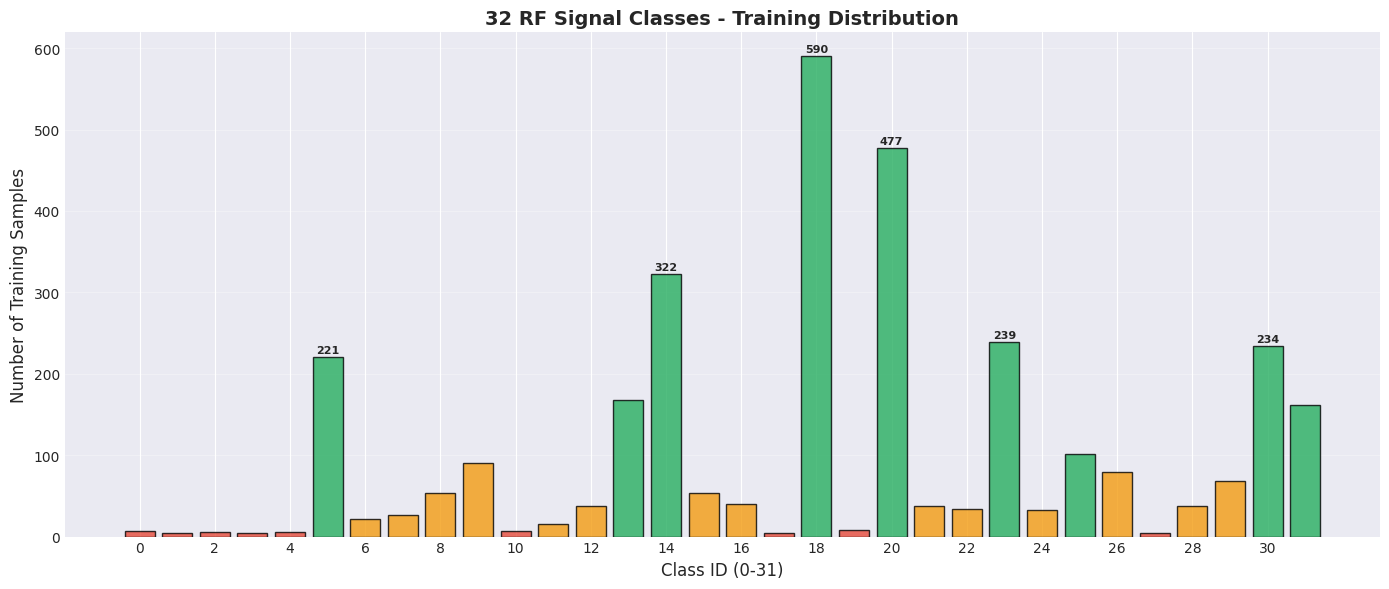

In [4]:
fig, ax = plt.subplots(figsize=(14, 6))

colors = ['#e74c3c' if c < 10 else '#f39c12' if c < 100 else '#27ae60' 
          for c in class_counts.values]

bars = ax.bar(range(len(class_counts)), class_counts.values, color=colors, edgecolor='black', alpha=0.8)
ax.set_xlabel('Class ID (0-31)', fontsize=12)
ax.set_ylabel('Number of Training Samples', fontsize=12)
ax.set_title('32 RF Signal Classes - Training Distribution', fontsize=14, fontweight='bold')
ax.set_xticks(range(0, 32, 2))

for i, (bar, count) in enumerate(zip(bars, class_counts.values)):
    if count > 200:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
                str(count), ha='center', fontsize=8, fontweight='bold')

ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# ─────────────────────────────────────────────
# Find image root directory
# ─────────────────────────────────────────────
def find_image_root():
    for dirpath, _, filenames in os.walk('/kaggle/input'):
        if 'waterfall' in dirpath.lower():
            return dirpath
    return '/kaggle/input/datasets/halcy0nic/radio-frequecy-rf-signal-image-classification/datasets/waterfall/'

IMAGE_ROOT = find_image_root()
print(f"📁 IMAGE_ROOT = {IMAGE_ROOT}")

# Build a flat index: filename → full path
FILE_INDEX = {}
if os.path.exists(IMAGE_ROOT):
    for dirpath, _, filenames in os.walk(IMAGE_ROOT):
        for fname in filenames:
            if fname.endswith(('.png', '.jpg', '.jpeg')):
                FILE_INDEX[fname] = os.path.join(dirpath, fname)

print(f"✅ Indexed {len(FILE_INDEX)} image files")

📁 IMAGE_ROOT = /kaggle/input/datasets/halcy0nic/radio-frequecy-rf-signal-image-classification/datasets/waterfall
✅ Indexed 3986 image files


##  Resolve Image Paths

Now we map each row in the CSV to its actual file path on disk.
The function tries multiple strategies in order:
1. Direct filename lookup in our index
2. The `full_path` column from the CSV
3. Class-name subfolder structure

Rows where no image is found are dropped from training.

In [6]:
def resolve_path(row):
    img_id = str(row['image_id']).strip()
    if img_id in FILE_INDEX:
        return FILE_INDEX[img_id]
    fp = str(row.get('full_path', '')).strip().lstrip('/')
    for prefix in ['/kaggle/input/', '/kaggle/input/datasets/', '']:
        p = os.path.join(prefix, fp)
        if os.path.exists(p):
            return p
    cls = str(row.get('class_name', '')).strip()
    if cls:
        p = os.path.join(IMAGE_ROOT, cls, img_id)
        if os.path.exists(p):
            return p
    return None

# Apply to both dataframes
train_df['path'] = train_df.apply(resolve_path, axis=1)
test_df['path']  = test_df.apply(resolve_path, axis=1)

# Drop unresolved train rows
missing_train = train_df['path'].isna().sum()
missing_test  = test_df['path'].isna().sum()

train_df = train_df[train_df['path'].notna()].reset_index(drop=True)

print(f"✅ Train images resolved : {len(train_df)}")
print(f"⚠️  Train images missing  : {missing_train}")
print(f"⚠️  Test  images missing  : {missing_test}")

✅ Train images resolved : 3194
⚠️  Train images missing  : 0
⚠️  Test  images missing  : 0


##  Encode Labels & Train/Validation Split

Before feeding data into the model, we need to:
- **Encode class IDs** into consecutive integers (0, 1, 2, ...) using `LabelEncoder` — neural networks need clean integer indices, not arbitrary class IDs
- **Split** our training data into a train set (90%) and a validation set (10%) using stratified sampling, meaning each class keeps its original proportion in both splits

In [14]:

# ─────────────────────────────────────────────
# Global Configuration
# ─────────────────────────────────────────────
IMG_SIZE     = 224
BATCH_SIZE   = 32
NUM_EPOCHS   = 30
LR           = 3e-4
WEIGHT_DECAY = 1e-4
RANDOM_STATE = 42
TTA_STEPS    = 7

# TPU device
DEVICE = xm.xla_device()

print("✅ Config set!")
print(f"   IMG_SIZE     : {IMG_SIZE}")
print(f"   BATCH_SIZE   : {BATCH_SIZE}")
print(f"   NUM_EPOCHS   : {NUM_EPOCHS}")
print(f"   LR           : {LR}")
print(f"   RANDOM_STATE : {RANDOM_STATE}")
print(f"   DEVICE       : {DEVICE}")

✅ Config set!
   IMG_SIZE     : 224
   BATCH_SIZE   : 32
   NUM_EPOCHS   : 30
   LR           : 0.0003
   RANDOM_STATE : 42
   DEVICE       : xla:0


In [9]:
# Encode class labels
le = LabelEncoder()
train_df['label'] = le.fit_transform(train_df['class_id'])
n_classes = len(le.classes_)

print(f"✅ Number of classes : {n_classes}")
print(f"   Label range      : {train_df['label'].min()} → {train_df['label'].max()}")

# Stratified train/val split
train_idx, val_idx = train_test_split(
    range(len(train_df)),
    test_size=0.1,
    stratify=train_df['label'],
    random_state=RANDOM_STATE
)

train_subset = train_df.iloc[train_idx].reset_index(drop=True)
val_subset   = train_df.iloc[val_idx].reset_index(drop=True)

print(f"\n📊 Split Summary:")
print(f"   Train samples : {len(train_subset)} ({len(train_subset)/len(train_df)*100:.1f}%)")
print(f"   Val   samples : {len(val_subset)}  ({len(val_subset)/len(train_df)*100:.1f}%)")

# Verify stratification worked
print(f"\n   Classes in train : {train_subset['label'].nunique()}")
print(f"   Classes in val   : {val_subset['label'].nunique()}")

✅ Number of classes : 32
   Label range      : 0 → 31

📊 Split Summary:
   Train samples : 2874 (90.0%)
   Val   samples : 320  (10.0%)

   Classes in train : 32
   Classes in val   : 29


##  Define Image Transforms & Augmentations

We define three separate transform pipelines:

- **Train transforms** — aggressive augmentation to help the model generalize and avoid overfitting. Since we have limited data (especially for rare classes), augmentation artificially expands our dataset diversity
- **Val transforms** — minimal processing, just resize and normalize. We want clean unmodified images for honest evaluation
- **TTA transforms** — used at inference time to get multiple slightly different versions of each test image and average the predictions (Test Time Augmentation)

All images are normalized using ImageNet mean and std since we're using a pretrained EfficientNet

In [11]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

tta_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

print("✅ Transforms defined!")
print(f"\n🟢 Train augmentations:")
for t in train_transform.transforms:
    print(f"   → {t.__class__.__name__}")

print(f"\n🔵 Val transforms:")
for t in val_transform.transforms:
    print(f"   → {t.__class__.__name__}")

✅ Transforms defined!

🟢 Train augmentations:
   → Resize
   → RandomHorizontalFlip
   → RandomVerticalFlip
   → ColorJitter
   → RandomRotation
   → RandomAffine
   → ToTensor
   → Normalize

🔵 Val transforms:
   → Resize
   → ToTensor
   → Normalize


##  Build Dataset Class & DataLoaders

We create a custom PyTorch `Dataset` class called `RFDataset` that:
- Loads each image from disk using its resolved path
- Applies the appropriate transform pipeline
- Returns `(image, label)` for training, or `(image, image_id)` for test (since we don't have labels)
- Handles corrupt/missing images gracefully by returning a blank black image instead of crashing

Then we wrap everything in PyTorch `DataLoader` objects which handle:
- **Batching** — grouping images into batches of 32
- **Shuffling** — randomizing order each epoch during training
- **Parallel loading** — loading images in background workers

In [12]:
class RFDataset(Dataset):
    def __init__(self, df, transform=None, has_labels=True):
        self.df         = df
        self.transform  = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        path = row['path']
        try:
            img = Image.open(path).convert('RGB')
        except Exception:
            # Fallback: blank black image if file is corrupt or missing
            img = Image.new('RGB', (IMG_SIZE, IMG_SIZE), color=0)
        if self.transform:
            img = self.transform(img)
        if self.has_labels:
            return img, int(row['label'])
        return img, str(row['image_id']).strip()

# Instantiate datasets
train_dataset = RFDataset(train_subset, transform=train_transform)
val_dataset   = RFDataset(val_subset,   transform=val_transform)

# Instantiate dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)

print("✅ Datasets and DataLoaders ready!")
print(f"\n📊 Summary:")
print(f"   Train samples  : {len(train_dataset)}")
print(f"   Val   samples  : {len(val_dataset)}")
print(f"   Train batches  : {len(train_loader)}")
print(f"   Val   batches  : {len(val_loader)}")

# Quick sanity check — load one batch
images, labels = next(iter(train_loader))
print(f"\n🔍 Sample batch:")
print(f"   Image tensor shape : {images.shape}  (batch x channels x H x W)")
print(f"   Labels shape       : {labels.shape}")
print(f"   Label values       : {labels[:8].tolist()}")

✅ Datasets and DataLoaders ready!

📊 Summary:
   Train samples  : 2874
   Val   samples  : 320
   Train batches  : 90
   Val   batches  : 10

🔍 Sample batch:
   Image tensor shape : torch.Size([32, 3, 224, 224])  (batch x channels x H x W)
   Labels shape       : torch.Size([32])
   Label values       : [19, 23, 5, 18, 20, 5, 9, 3]


## Build EfficientNet-B0 Model

We use **EfficientNet-B0** pretrained on ImageNet as our backbone. This is called **Transfer Learning** — instead of training from scratch, we start with a model that already understands low-level visual features (edges, textures, shapes) and fine-tune it for our specific task.

The key modification is replacing the original classifier head (built for 1000 ImageNet classes) with our own custom head for 32 RF signal classes:

In [15]:
print("🔧 Loading pretrained EfficientNet-B0...")
model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
)

# Replace classifier head
in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.BatchNorm1d(512),
    nn.Dropout(p=0.3),
    nn.Linear(512, n_classes)
)

# Move to TPU
model = model.to(DEVICE)

# Separate parameter groups for differential LR
backbone_params = list(model.features.parameters())
head_params     = list(model.classifier.parameters())

# Loss, optimizer, scheduler
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': LR * 0.1},
    {'params': head_params,     'lr': LR}
], weight_decay=WEIGHT_DECAY)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# Print model summary
total_params    = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✅ Model ready on TPU!")
print(f"\n📊 Model Summary:")
print(f"   Backbone        : EfficientNet-B0 (ImageNet pretrained)")
print(f"   Total params    : {total_params:,}")
print(f"   Trainable params: {trainable_params:,}")
print(f"   Output classes  : {n_classes}")
print(f"\n⚙️  Training Config:")
print(f"   Backbone LR     : {LR * 0.1}")
print(f"   Head LR         : {LR}")
print(f"   Weight decay    : {WEIGHT_DECAY}")
print(f"   Label smoothing : 0.1")
print(f"   Scheduler       : CosineAnnealingLR")

🔧 Loading pretrained EfficientNet-B0...
✅ Model ready on TPU!

📊 Model Summary:
   Backbone        : EfficientNet-B0 (ImageNet pretrained)
   Total params    : 4,680,860
   Trainable params: 4,680,860
   Output classes  : 32

⚙️  Training Config:
   Backbone LR     : 2.9999999999999997e-05
   Head LR         : 0.0003
   Weight decay    : 0.0001
   Label smoothing : 0.1
   Scheduler       : CosineAnnealingLR


##  Training Loop

This is the core training loop. Each epoch consists of two phases:

- **Training phase** — model learns by forward pass → compute loss → backward pass → update weights
- **Validation phase** — model is evaluated on unseen data with no gradient updates

We also implement:
- **Early stopping** — halt training if validation accuracy doesn't improve for 7 consecutive epochs, preventing overfitting
- **Model checkpointing** — save the best model weights whenever validation accuracy improves
- **TPU optimization** — using `xm.optimizer_step()` and `pl.MpDeviceLoader` instead of standard PyTorch equivalents for TPU compatibility

In [16]:
best_val_acc    = 0.0
best_model_path = '/kaggle/working/best_model.pth'
patience        = 7
no_improve      = 0

print("🚀 Starting Training...")
print(f"   Epochs     : {NUM_EPOCHS}")
print(f"   Batch size : {BATCH_SIZE}")
print(f"   Patience   : {patience}")
print("-" * 65)

for epoch in range(NUM_EPOCHS):
    # ── Train Phase ──
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    train_device_loader = pl.MpDeviceLoader(train_loader, DEVICE)

    for images, labels in train_device_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()

        # TPU specific optimizer step
        xm.optimizer_step(optimizer)

        train_loss    += loss.item()
        preds          = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total   += labels.size(0)

    train_acc = train_correct / train_total

    # ── Validation Phase ──
    model.eval()
    val_correct, val_total = 0, 0
    val_device_loader = pl.MpDeviceLoader(val_loader, DEVICE)

    with torch.no_grad():
        for images, labels in val_device_loader:
            outputs      = model(images)
            preds        = outputs.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += labels.size(0)

    val_acc = val_correct / val_total
    scheduler.step()

    # Sync TPU before printing
    xm.mark_step()

    print(f"   Epoch {epoch+1:>2}/{NUM_EPOCHS} | "
          f"Loss: {train_loss/len(train_loader):.4f} | "
          f"Train: {train_acc:.4f} | "
          f"Val: {val_acc:.4f} | "
          f"LR: {scheduler.get_last_lr()[0]:.6f}")

    # ── Checkpoint ──
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        xm.save(model.state_dict(), best_model_path)
        print(f"   ✅ Best model saved! Val Acc: {best_val_acc:.4f}")
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"   ⏹ Early stopping at epoch {epoch+1}")
            break

print(f"\n🏆 Best Validation Accuracy: {best_val_acc:.4f}")

🚀 Starting Training...
   Epochs     : 30
   Batch size : 32
   Patience   : 7
-----------------------------------------------------------------
   Epoch  1/30 | Loss: 2.3257 | Train: 0.4972 | Val: 0.7750 | LR: 0.000030
   ✅ Best model saved! Val Acc: 0.7750
   Epoch  2/30 | Loss: 1.4034 | Train: 0.7912 | Val: 0.8438 | LR: 0.000030
   ✅ Best model saved! Val Acc: 0.8438
   Epoch  3/30 | Loss: 1.2001 | Train: 0.8424 | Val: 0.8812 | LR: 0.000029
   ✅ Best model saved! Val Acc: 0.8812
   Epoch  4/30 | Loss: 1.1035 | Train: 0.8782 | Val: 0.9062 | LR: 0.000029
   ✅ Best model saved! Val Acc: 0.9062
   Epoch  5/30 | Loss: 1.0446 | Train: 0.8960 | Val: 0.9187 | LR: 0.000028
   ✅ Best model saved! Val Acc: 0.9187
   Epoch  6/30 | Loss: 1.0073 | Train: 0.9092 | Val: 0.9313 | LR: 0.000027
   ✅ Best model saved! Val Acc: 0.9313
   Epoch  7/30 | Loss: 0.9755 | Train: 0.9130 | Val: 0.9250 | LR: 0.000026
   Epoch  8/30 | Loss: 0.9393 | Train: 0.9269 | Val: 0.9469 | LR: 0.000025
   ✅ Best model saved

In [17]:
# ─────────────────────────────────────────────
# STEP 7: TTA Predictions + Submission
# ─────────────────────────────────────────────
print("\n[7/7] Generating predictions with TTA...")

# Load best model back onto TPU
model.load_state_dict(torch.load(best_model_path))
model = model.to(DEVICE)
model.eval()

test_df_valid  = test_df[test_df['path'].notna()].reset_index(drop=True)
majority_class = int(train_df['class_id'].value_counts().idxmax())
all_probs      = []
final_ids      = []

for tta_step in range(TTA_STEPS):
    t = val_transform if tta_step == 0 else tta_transform
    test_dataset = RFDataset(test_df_valid, transform=t, has_labels=False)
    test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0)
    test_device_loader = pl.MpDeviceLoader(test_loader, DEVICE)

    step_probs, step_ids = [], []
    with torch.no_grad():
        for images, img_ids in test_device_loader:
            outputs = model(images)
            probs   = torch.softmax(outputs, dim=1).cpu().numpy()
            step_probs.append(probs)
            step_ids.extend(img_ids)

    xm.mark_step()
    all_probs.append(np.vstack(step_probs))
    if tta_step == 0:
        final_ids = step_ids
    print(f"   TTA step {tta_step+1}/{TTA_STEPS} done")

avg_probs    = np.mean(all_probs, axis=0)
pred_encoded = avg_probs.argmax(axis=1)
pred_classes = le.inverse_transform(pred_encoded)
id_to_pred   = dict(zip(final_ids, pred_classes))

final_preds = [
    id_to_pred.get(str(row['image_id']).strip(), majority_class)
    for _, row in test_df.iterrows()
]

submission = pd.DataFrame({
    'image_id': test_df['image_id'],
    'predicted_class': final_preds
})
submission.to_csv('submission.csv', index=False, header=True)

with open('submission.csv') as f:
    rows = sum(1 for _ in f) - 1

print(f"\n{'='*65}")
print(f"  Submission Summary")
print(f"{'='*65}")
print(f"  Expected rows    : {len(test_df)}")
print(f"  Actual rows      : {rows}")
print(f"  Status           : {'✅ PERFECT' if rows == len(test_df) else '❌ ROW MISMATCH'}")
print(f"  Best Val Accuracy: {best_val_acc:.4f}")
print(f"\n  Prediction distribution (top 10):")
pred_s = pd.Series(final_preds)
for cid, cnt in pred_s.value_counts().head(10).items():
    nm = train_df[train_df['class_id'] == cid]['class_name'].values
    name = nm[0] if len(nm) > 0 else '?'
    print(f"    class {cid:>3} ({name:<32}) → {cnt:>5}")

print("\nFirst 3 lines of submission.csv:")
with open('submission.csv') as f:
    for i, line in enumerate(f):
        if i < 3:
            print(f"  {line.strip()}")

print("\n✅ Done! Ready to submit.")


[7/7] Generating predictions with TTA...
   TTA step 1/7 done
   TTA step 2/7 done
   TTA step 3/7 done
   TTA step 4/7 done
   TTA step 5/7 done
   TTA step 6/7 done
   TTA step 7/7 done

  Submission Summary
  Expected rows    : 799
  Actual rows      : 799
  Status           : ✅ PERFECT
  Best Val Accuracy: 0.9469

  Prediction distribution (top 10):
    class  18 (fm                              ) →   147
    class  20 (lora                            ) →   118
    class  14 (cellular                        ) →    87
    class  23 (packet                          ) →    60
    class  30 (wifi                            ) →    58
    class   5 (RS41-Radiosonde                 ) →    55
    class  31 (z-wave                          ) →    44
    class  13 (bluetooth                       ) →    40
    class  25 (remote-keyless-entry            ) →    26
    class   9 (ais                             ) →    21

First 3 lines of submission.csv:
  image_id,predicted_class
  4b8da178f2

In [ ]:
# ─────────────────────────────────────────────
# Generate and Save Confusion Matrix
# ─────────────────────────────────────────────
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
all_val_preds = []
all_val_labels = []

val_device_loader = pl.MpDeviceLoader(val_loader, DEVICE)

with torch.no_grad():
    for images, labels in val_device_loader:
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_val_preds.extend(preds.cpu().numpy())
        all_val_labels.extend(labels.cpu().numpy())

# Compute matrix using target names from your LabelEncoder
cm = confusion_matrix(all_val_labels, all_val_preds)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=ax)
ax.set_xlabel('Predicted Label Index', fontsize=12)
ax.set_ylabel('True Label Index', fontsize=12)
ax.set_title('32-Class RF Signal Classification - Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()

# Save it to put alongside your leaderboard screenshot in your GitHub images folder
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

print("✅ Confusion matrix generated and saved successfully!")
